# Online Shoppers Purchasing Intention — Logistic Regression

**Module:** Fundamentals of Machine Learning — Programming Assignment
**Algorithm:** Logistic Regression (supervised classification)
**Author:** MS26929828

**Problem:** Predict whether a website session ends in a purchase (`Revenue = True`) from the visitor's browsing behaviour.

**Dataset:** Online Shoppers Purchasing Intention Dataset - https://www.kaggle.com/datasets/imakash3011/online-shoppers-purchasing-intention-dataset

**Notebook outline**
1. Setup and data loading
2. Data overview
3. Preprocessing (shared settings with the Random Forest notebook)
4. Baseline Logistic Regression
5. Hyperparameter tuning with cross-validation
6. Evaluation on the test set
7. Decision-threshold analysis
8. Model interpretation (coefficients / odds ratios)
9. Saving results for the comparison notebook
10. Summary

## 1. Setup and data loading

In [1]:
import json
import os
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve,
                             precision_recall_curve)

warnings.filterwarnings("ignore", category=FutureWarning)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
DATA_PATH = "https://raw.githubusercontent.com/Ashinsanie/ML-assignment/refs/heads/main/data/online_shoppers_intention.csv"

df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
df.head()

Shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


## 2. Data overview

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Administrative           12330 non-null  int64  
 1   Administrative_Duration  12330 non-null  float64
 2   Informational            12330 non-null  int64  
 3   Informational_Duration   12330 non-null  float64
 4   ProductRelated           12330 non-null  int64  
 5   ProductRelated_Duration  12330 non-null  float64
 6   BounceRates              12330 non-null  float64
 7   ExitRates                12330 non-null  float64
 8   PageValues               12330 non-null  float64
 9   SpecialDay               12330 non-null  float64
 10  Month                    12330 non-null  object 
 11  OperatingSystems         12330 non-null  int64  
 12  Browser                  12330 non-null  int64  
 13  Region                   12330 non-null  int64  
 14  TrafficType           

In [4]:
print("Missing values in the whole dataset:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values in the whole dataset: 0
Duplicate rows: 125


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Administrative,12330.0,2.315166,3.321784,0.0,0.000000,1.000000,4.000000,27.000000
Administrative_Duration,12330.0,80.818611,176.779107,0.0,0.000000,7.500000,93.256250,3398.750000
Informational,12330.0,0.503569,1.270156,0.0,0.000000,0.000000,0.000000,24.000000
Informational_Duration,12330.0,34.472398,140.749294,0.0,0.000000,0.000000,0.000000,2549.375000
ProductRelated,12330.0,31.731468,44.475503,0.0,7.000000,18.000000,38.000000,705.000000
ProductRelated_Duration,12330.0,1194.746220,1913.669288,0.0,184.137500,598.936905,1464.157214,63973.522230
BounceRates,12330.0,0.022191,0.048488,0.0,0.000000,0.003112,0.016813,0.200000
ExitRates,12330.0,0.043073,0.048597,0.0,0.014286,0.025156,0.050000,0.200000
PageValues,12330.0,5.889258,18.568437,0.0,0.000000,0.000000,0.000000,361.763742
SpecialDay,12330.0,0.061427,0.198917,0.0,0.000000,0.000000,0.000000,1.000000


False    10422
True      1908
Name: Revenue, dtype: int64

Percentage that purchased: 15.47%


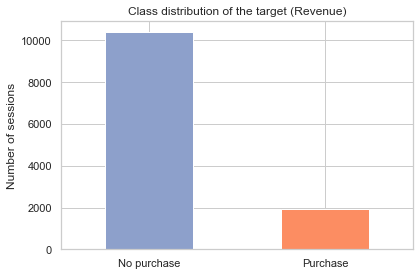

In [6]:
counts = df["Revenue"].value_counts()
print(counts)
print("\nPercentage that purchased: {:.2f}%".format(100 * counts[True] / len(df)))

ax = counts.rename({False: "No purchase", True: "Purchase"}).plot(kind="bar", color=["#8da0cb", "#fc8d62"], rot=0)
ax.set_title("Class distribution of the target (Revenue)")
ax.set_ylabel("Number of sessions")
plt.tight_layout()
plt.show()

The target is imbalanced: only about 15% of sessions end in a purchase. A model that always predicts
"no purchase" would already reach about 85% accuracy, so accuracy alone is misleading. We therefore also
report precision, recall, F1-score, ROC-AUC and PR-AUC for the positive (purchase) class.

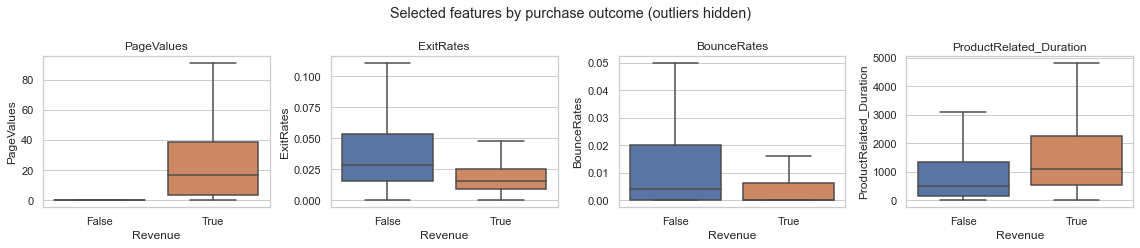

In [7]:
num_preview = ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, col in zip(axes, num_preview):
    sns.boxplot(data=df, x="Revenue", y=col, ax=ax, showfliers=False)
    ax.set_title(col)
plt.suptitle("Selected features by purchase outcome (outliers hidden)")
plt.tight_layout()
plt.show()

`PageValues` is clearly higher for sessions that end in a purchase, while `ExitRates` and `BounceRates` are lower.
The numeric features are also strongly right-skewed (many zeros and a few very large values), which matters
for Logistic Regression because it is sensitive to feature scale and extreme values.

Preprocessing 


In [9]:
RANDOM_STATE = 42
TEST_SIZE = 0.2

data = df.drop_duplicates().reset_index(drop=True)
data["Weekend"] = data["Weekend"].astype(int)
data["Revenue"] = data["Revenue"].astype(int)
print("Rows after removing duplicates:", len(data))

numeric_features = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
                    "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
                    "PageValues", "SpecialDay"]
categorical_features = ["Month", "VisitorType", "OperatingSystems", "Browser", "Region", "TrafficType"]
binary_features = ["Weekend"]

X = data[numeric_features + categorical_features + binary_features]
y = data["Revenue"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)

print("Training set:", X_train.shape, " purchase rate = {:.3f}".format(y_train.mean()))
print("Test set:    ", X_test.shape, " purchase rate = {:.3f}".format(y_test.mean()))

Rows after removing duplicates: 12205
Training set: (9764, 17)  purchase rate = 0.156
Test set:     (2441, 17)  purchase rate = 0.156


In [10]:
numeric_pipeline = Pipeline([
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ("bin", "passthrough", binary_features),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Baseline Logistic Regression

Logistic Regression models the probability of a purchase as

$$P(\text{purchase} \mid x) = \sigma(w^\top x + b) = \frac{1}{1 + e^{-(w^\top x + b)}}$$

and predicts "purchase" when this probability is at least 0.5. We first train it with default settings as a baseline.

In [11]:
def evaluate(model, X_eval, y_eval, threshold=0.5):
    """Return the main classification metrics for the purchase (positive) class."""
    proba = model.predict_proba(X_eval)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "Accuracy": accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred),
        "Recall": recall_score(y_eval, pred),
        "F1-score": f1_score(y_eval, pred),
        "ROC-AUC": roc_auc_score(y_eval, proba),
        "PR-AUC": average_precision_score(y_eval, proba),
    }

baseline = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
])
baseline.fit(X_train, y_train)

baseline_metrics = evaluate(baseline, X_test, y_test)
pd.Series(baseline_metrics, name="Baseline LR (test)").round(4).to_frame()

,Baseline LR (test)
Accuracy,0.9000
Precision,0.7184
Recall,0.5942
F1-score,0.6504
ROC-AUC,0.9217
PR-AUC,0.6954


The baseline reaches about 90% accuracy and a ROC-AUC of about 0.92, but its recall for the purchase class is only
about 0.59: with the default settings it misses roughly 4 in 10 real buyers, because the rare purchase class has little
influence on training. Tuning should address this.

Hyperparameter tuning with cross-validation 

We use `GridSearchCV` with 5-fold stratified cross-validation on the training set only, optimising F1-score
(a balance of precision and recall that suits imbalanced data). Hyperparameters searched:

| Hyperparameter | Values | Meaning |
|---|---|---|
| `C` | 0.001 – 100 | Inverse of regularisation strength (smaller = simpler model) |
| `penalty` | L1, L2 | L1 can shrink some coefficients to exactly zero (feature selection); L2 shrinks all smoothly |
| `class_weight` | None, balanced | `balanced` gives more weight to the rare purchase class |

In [13]:
param_grid = {
    "clf__C": [0.001, 0.01, 0.1, 1, 10, 100],
    "clf__penalty": ["l1", "l2"],
    "clf__class_weight": [None, "balanced"],
}

lr_pipeline = Pipeline([
    ("prep", preprocessor),
    ("clf", LogisticRegression(solver="liblinear", max_iter=2000, random_state=RANDOM_STATE)),
])

grid = GridSearchCV(lr_pipeline, param_grid, scoring="f1", cv=cv, n_jobs=-1,
                    return_train_score=True)

start = time.time()
grid.fit(X_train, y_train)
tuning_time = time.time() - start

print("Best parameters:", grid.best_params_)
print("Best mean CV F1-score: {:.4f}".format(grid.best_score_))
print("Tuning time: {:.1f} s".format(tuning_time))

Best parameters: {'clf__C': 0.01, 'clf__class_weight': 'balanced', 'clf__penalty': 'l1'}
Best mean CV F1-score: 0.6708
Tuning time: 10.8 s


In [14]:
cv_results = pd.DataFrame(grid.cv_results_)
summary = (cv_results[["param_clf__C", "param_clf__penalty", "param_clf__class_weight",
                       "mean_train_score", "mean_test_score", "std_test_score"]]
           .rename(columns={"param_clf__C": "C", "param_clf__penalty": "penalty",
                            "param_clf__class_weight": "class_weight",
                            "mean_train_score": "train F1", "mean_test_score": "CV F1",
                            "std_test_score": "CV F1 std"})
           .sort_values("CV F1", ascending=False))
summary.head(10).round(4)

,C,penalty,class_weight,train F1,CV F1,CV F1 std
6,0.01,l1,balanced,0.6709,0.6708,0.0155
7,0.01,l2,balanced,0.6676,0.6643,0.0105
2,0.001,l1,balanced,0.6630,0.6631,0.0104
3,0.001,l2,balanced,0.6603,0.6603,0.0125
10,0.1,l1,balanced,0.6607,0.6574,0.0164
11,0.1,l2,balanced,0.6621,0.6537,0.0157
14,1,l1,balanced,0.6579,0.6484,0.0133
15,1,l2,balanced,0.6581,0.6469,0.0135
19,10,l2,balanced,0.6577,0.6459,0.0129
18,10,l1,balanced,0.6576,0.6457,0.0127


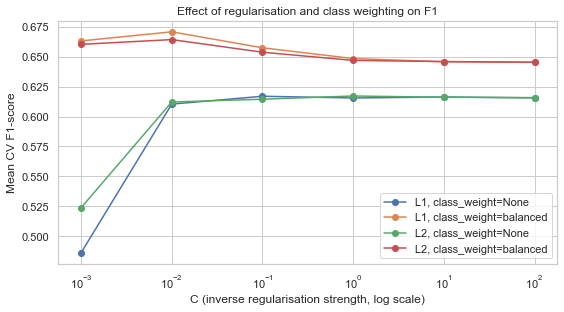

In [15]:
plot_df = cv_results.copy()
plot_df["setting"] = (plot_df["param_clf__penalty"].astype(str).str.upper() + ", class_weight=" +
                      plot_df["param_clf__class_weight"].map(lambda v: "balanced" if v == "balanced" else "None"))
plt.figure(figsize=(8, 4.5))
for setting, g in plot_df.groupby("setting"):
    g = g.sort_values("param_clf__C")
    plt.plot(g["param_clf__C"].astype(float), g["mean_test_score"], marker="o", label=setting)
plt.xscale("log")
plt.xlabel("C (inverse regularisation strength, log scale)")
plt.ylabel("Mean CV F1-score")
plt.title("Effect of regularisation and class weighting on F1")
plt.legend()
plt.tight_layout()
plt.show()

Every top-ranked combination uses `class_weight="balanced"`: giving the rare purchase class more weight raises CV F1 from about 0.62 to about 0.67.

The best setting is `C = 0.01` with an L1 penalty, i.e. fairly strong regularisation. Larger values of `C` give slightly lower CV F1, so a simpler model generalises better here.

Training F1 and cross-validation F1 are almost identical (difference < 0.01), so the model is not overfitting.Logistic Regression is a linear model with limited capacity, so underfitting is the bigger risk than overfitting.

In [16]:
#Evaluation on the test set

best_lr = grid.best_estimator_

start = time.time()
best_lr.fit(X_train, y_train)
train_time = time.time() - start

start = time.time()
y_proba = best_lr.predict_proba(X_test)[:, 1]
predict_time = time.time() - start
y_pred = (y_proba >= 0.5).astype(int)

tuned_metrics = evaluate(best_lr, X_test, y_test)
comparison = pd.DataFrame({"Baseline LR": baseline_metrics, "Tuned LR": tuned_metrics}).round(4)
print("Training time: {:.3f} s | Prediction time: {:.4f} s".format(train_time, predict_time))
comparison

Training time: 0.061 s | Prediction time: 0.0100 s


,Baseline LR,Tuned LR
Accuracy,0.9000,0.8845
Precision,0.7184,0.5988
Recall,0.5942,0.7932
F1-score,0.6504,0.6824
ROC-AUC,0.9217,0.9243
PR-AUC,0.6954,0.6832


In [18]:
print(classification_report(y_test, y_pred, target_names=["No purchase", "Purchase"], digits=4))

              precision    recall  f1-score   support

 No purchase     0.9592    0.9014    0.9294      2059
    Purchase     0.5988    0.7932    0.6824       382

    accuracy                         0.8845      2441
   macro avg     0.7790    0.8473    0.8059      2441
weighted avg     0.9028    0.8845    0.8907      2441



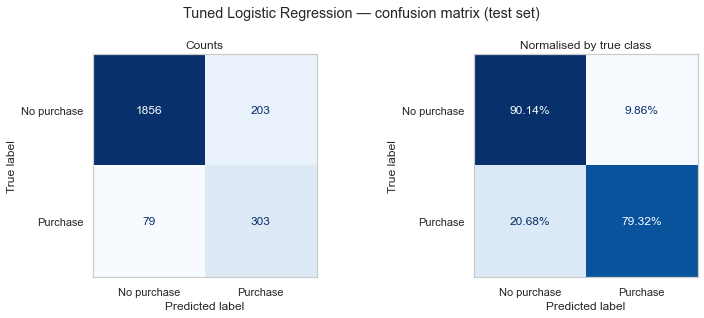

True negatives: 1856  False positives: 203  False negatives: 79  True positives: 303


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["No purchase", "Purchase"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Counts")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, normalize="true"),
                       display_labels=["No purchase", "Purchase"]).plot(ax=axes[1], cmap="Blues",
                                                                         colorbar=False, values_format=".2%")
axes[1].set_title("Normalised by true class")
for ax in axes:
    ax.grid(False)
plt.suptitle("Tuned Logistic Regression — confusion matrix (test set)")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True negatives: {tn}  False positives: {fp}  False negatives: {fn}  True positives: {tp}")

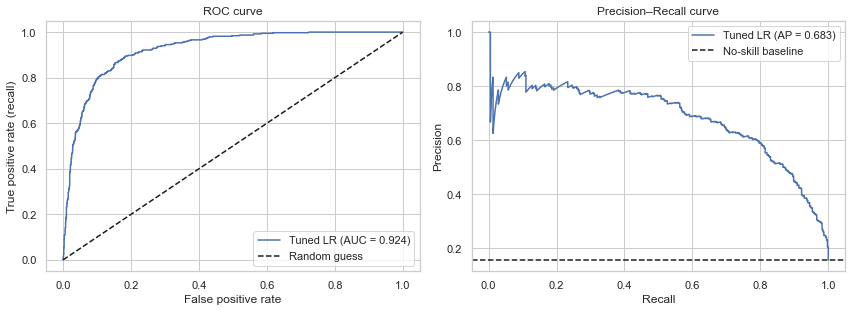

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[0].plot(fpr, tpr, label="Tuned LR (AUC = {:.3f})".format(tuned_metrics["ROC-AUC"]))
axes[0].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[0].set_xlabel("False positive rate")
axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curve")
axes[0].legend()

prec, rec, _ = precision_recall_curve(y_test, y_proba)
axes[1].plot(rec, prec, label="Tuned LR (AP = {:.3f})".format(tuned_metrics["PR-AUC"]))
axes[1].axhline(y_test.mean(), color="k", linestyle="--", label="No-skill baseline")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–Recall curve")
axes[1].legend()

plt.tight_layout()
plt.show()

Decision-threshold analysis

The default rule predicts "purchase" when the probability is at least 0.5, but this is not necessarily the best
threshold. To choose a threshold without looking at the test set, we use out-of-fold cross-validated
probabilities on the training data, find the threshold that maximises F1, and only then apply it to the test set.

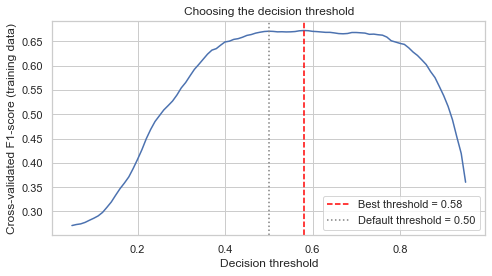

,Baseline LR,Tuned LR,Tuned LR (threshold 0.58)
Accuracy,0.9000,0.8845,0.8853
Precision,0.7184,0.5988,0.6037
Recall,0.5942,0.7932,0.7775
F1-score,0.6504,0.6824,0.6796
ROC-AUC,0.9217,0.9243,0.9243
PR-AUC,0.6954,0.6832,0.6832


In [20]:
oof_proba = cross_val_predict(best_lr, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
f1_by_threshold = [f1_score(y_train, (oof_proba >= t).astype(int)) for t in thresholds]
best_threshold = float(thresholds[int(np.argmax(f1_by_threshold))])

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1_by_threshold)
plt.axvline(best_threshold, color="red", linestyle="--", label=f"Best threshold = {best_threshold:.2f}")
plt.axvline(0.5, color="grey", linestyle=":", label="Default threshold = 0.50")
plt.xlabel("Decision threshold")
plt.ylabel("Cross-validated F1-score (training data)")
plt.title("Choosing the decision threshold")
plt.legend()
plt.tight_layout()
plt.show()

threshold_metrics = evaluate(best_lr, X_test, y_test, threshold=best_threshold)
comparison[f"Tuned LR (threshold {best_threshold:.2f})"] = pd.Series(threshold_metrics).round(4)
comparison

The threshold chosen on the training data (0.58) is close to 0.5 and gives almost the same test F1 — because
`class_weight="balanced"` already shifts the model towards the purchase class, the default threshold is close to optimal.
Moving the threshold mainly trades precision against recall; ROC-AUC and PR-AUC do not change, because they measure
ranking quality across all thresholds. In practice the threshold is a business decision: a shop that wants to reach as
many likely buyers as possible (e.g. with a discount pop-up) would accept lower precision for higher recall.

Model Interpretation

A key advantage of Logistic Regression is that it is interpretable: each coefficient shows how a feature changes
the log-odds of a purchase. Because numeric features were log-transformed and standardised, their coefficients can be
compared with each other. `exp(coefficient)` is the odds ratio — the factor by which the odds of a purchase are
multiplied for a one-standard-deviation increase (numeric) or for belonging to that category (one-hot).

In [21]:
feature_names = best_lr.named_steps["prep"].get_feature_names_out()
feature_names = [n.split("__", 1)[1] for n in feature_names]
coefs = best_lr.named_steps["clf"].coef_[0]

coef_df = (pd.DataFrame({"feature": feature_names, "coefficient": coefs})
           .assign(odds_ratio=lambda d: np.exp(d["coefficient"]),
                   abs_coef=lambda d: d["coefficient"].abs())
           .sort_values("abs_coef", ascending=False))

print("Features with a non-zero coefficient: {} of {}".format((coef_df["coefficient"] != 0).sum(), len(coef_df)))
nonzero = coef_df[coef_df["coefficient"] != 0].drop(columns="abs_coef")
nonzero.round(4)

Features with a non-zero coefficient: 8 of 73


,feature,coefficient,odds_ratio
8,PageValues,1.4035,4.0694
17,Month_Nov,0.7388,2.0935
16,Month_May,-0.4866,0.6147
22,VisitorType_Returning_Visitor,-0.4370,0.6460
7,ExitRates,-0.2459,0.7820
4,ProductRelated,0.1263,1.1346
2,Informational,0.0219,1.0221
0,Administrative,0.0100,1.0101


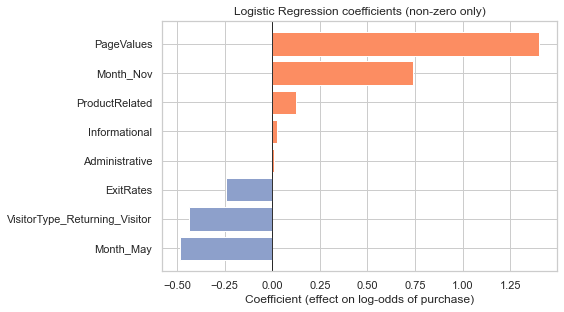

In [22]:
top = nonzero.sort_values("coefficient")
plt.figure(figsize=(8, 4.5))
plt.barh(top["feature"], top["coefficient"],
         color=["#fc8d62" if c > 0 else "#8da0cb" for c in top["coefficient"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (effect on log-odds of purchase)")
plt.title("Logistic Regression coefficients (non-zero only)")
plt.tight_layout()
plt.show()

Positive coefficients increase the probability of a purchase, negative ones decrease it.

The L1 penalty set most coefficients to exactly zero, keeping only 8 of 73 features — Logistic Regression has effectively performed feature selection.

`PageValues` has by far the strongest effect (odds ratio ≈ 4.1 per standard deviation). This makes sense: it measures how valuable the visited pages were in sessions that led to purchases.
 
Sessions in November (pre-holiday shopping) are more likely to convert, while May sessions are less likely.

Higher `ExitRates` lower the chance of buying, and returning visitors convert slightly less often than new visitors once the other features are taken into account.

Saving results for the comparison notebook

In [23]:
os.makedirs("../results", exist_ok=True)

results = {
    "model": "Logistic Regression",
    "best_params": {k.replace("clf__", ""): v for k, v in grid.best_params_.items()},
    "cv_best_f1": round(float(grid.best_score_), 4),
    "test_metrics_threshold_0.5": {k: round(float(v), 4) for k, v in tuned_metrics.items()},
    "best_threshold": round(best_threshold, 2),
    "test_metrics_best_threshold": {k: round(float(v), 4) for k, v in threshold_metrics.items()},
    "confusion_matrix_threshold_0.5": cm.tolist(),
    "training_time_s": round(train_time, 4),
    "tuning_time_s": round(tuning_time, 2),
}
with open("../results/logistic_regression_results.json", "w") as f:
    json.dump(results, f, indent=2)

# Save test-set probabilities so ROC/PR curves of both models can be plotted together later
pd.DataFrame({"y_true": y_test.values, "lr_proba": y_proba}).to_csv(
    "../results/logistic_regression_test_predictions.csv", index=False)

print(json.dumps(results, indent=2))

{
  "model": "Logistic Regression",
  "best_params": {
    "C": 0.01,
    "class_weight": "balanced",
    "penalty": "l1"
  },
  "cv_best_f1": 0.6708,
  "test_metrics_threshold_0.5": {
    "Accuracy": 0.8845,
    "Precision": 0.5988,
    "Recall": 0.7932,
    "F1-score": 0.6824,
    "ROC-AUC": 0.9243,
    "PR-AUC": 0.6832
  },
  "best_threshold": 0.58,
  "test_metrics_best_threshold": {
    "Accuracy": 0.8853,
    "Precision": 0.6037,
    "Recall": 0.7775,
    "F1-score": 0.6796,
    "ROC-AUC": 0.9243,
    "PR-AUC": 0.6832
  },
  "confusion_matrix_threshold_0.5": [
    [
      1856,
      203
    ],
    [
      79,
      303
    ]
  ],
  "training_time_s": 0.0608,
  "tuning_time_s": 10.77
}


Summery 

| Metric (test set, threshold 0.5) | Tuned Logistic Regression |
|---|---|
| Accuracy | 0.885 |
| Precision (purchase) | 0.599 |
| Recall (purchase) | 0.793 |
| F1-score (purchase) | 0.682 |
| ROC-AUC | 0.924 |
| PR-AUC | 0.683 |

Best hyperparameters:`C = 0.01`, L1 penalty, `class_weight = "balanced"` (selected by 5-fold CV on F1).

Key findings
- Tuning raised recall for buyers from 0.59 to 0.79 and F1 from 0.65 to 0.68, at the cost of lower precision and slightly
  lower accuracy — a better trade-off for an imbalanced problem where finding buyers is the goal.
- The model is fast (training takes well under a second) and highly interpretable; `PageValues`, month and exit rate
  are the main drivers of purchase probability.

Limitations
- Logistic Regression assumes a linear relationship between the (transformed) features and the log-odds of purchase,
  so it cannot capture interactions between features unless they are added by hand.
- Precision is moderate: about 4 in 10 sessions predicted as purchases do not actually buy.
- The data comes from a single online store over one year, so results may not generalise to other shops or periods.

These results are saved in `results/` and are compared with the Random Forest model in the comparison notebook.